<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_6/dataset_pbl/FAISS/praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Praktikum 2**
Pada percobaan kali ini kita akan membuat pencarian sederhana menggunakan FAISS. Install FAISS terlebih dahulu menggunakan FAISS-CPU, jika ingin menggunakan GPU, dapat lakukan instalasi FAISS-GPU.


In [1]:
!pip install faiss-cpu
#!pip install faiss-gpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 34.1 MB/s  0:00:00


Exact NN (Flat) indices: [[  0 106  68]] distances: [[0.         0.         0.01583839]]
IVF+PQ indices: [[  0 106  68]] distances: [[2.6822090e-07 2.6822090e-07 1.5918285e-02]]
Waktu Exact: 0.1867 ms
Waktu IVF+PQ: 0.2527 ms


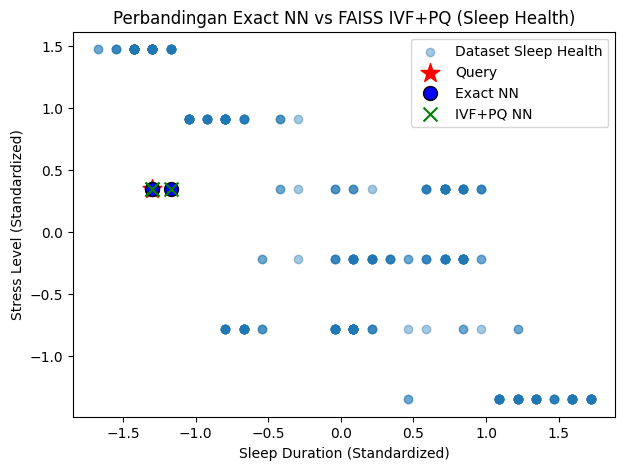

In [2]:
import numpy as np
import pandas as pd
import faiss
import matplotlib.pyplot as plt
import time
from sklearn.preprocessing import StandardScaler

# Load & Standarisasi Dataset Sleep Health (2 Fitur: Sleep Duration & Stress Level)
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')
fitur_2d = ['Sleep Duration', 'Stress Level']
X = StandardScaler().fit_transform(df[fitur_2d]).astype('float32')

# Ambil salah satu titik sebagai query (misalnya baris ke-0)
query = X[0:1].copy()

# Exact NN dengan IndexFlatL2 (brute force tapi cepat)
d = 2
index_flat = faiss.IndexFlatL2(d)  # L2 = Euclidean distance
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.time()
time_flat = end - start

# IVF + PQ (Approximate)
nlist = 10  # jumlah cluster (inverted list)
m = 2       # jumlah subvector (d=2 habis dibagi m=2)
quantizer = faiss.IndexFlatL2(d)
index_ivfpq = faiss.IndexIVFPQ(quantizer, d, nlist, m, 8)  # 8 bit per subvector
index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", round(time_flat * 1000, 4), "ms")
print("Waktu IVF+PQ:", round(time_ivfpq * 1000, 4), "ms")

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], alpha=0.4, label="Dataset Sleep Health")
plt.scatter(query[:, 0], query[:, 1], c='red', marker='*', s=200, label="Query")

# Tetangga dari Flat
plt.scatter(X[I_flat[0], 0], X[I_flat[0], 1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
plt.scatter(X[I_ivfpq[0], 0], X[I_ivfpq[0], 1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.xlabel("Sleep Duration (Standardized)")
plt.ylabel("Stress Level (Standardized)")
plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ (Sleep Health)")
plt.show()

In [3]:
# Siapkan 5 fitur numerik untuk eksperimen 5D
fitur_5d = ['Age', 'Sleep Duration', 'Quality of Sleep', 'Stress Level', 'Heart Rate']
X_5d_base = StandardScaler().fit_transform(df[fitur_5d]).astype('float32')

# Daftar kombinasi: (metric, jumlah_data, dimensi)
# 374 = jumlah data asli Sleep Health, 1000000 = simulasi duplikasi skala besar
configs = [
    ('L2', 374, 2),
    ('L2', 1000000, 2),
    ('L2', 374, 5),
    ('L2', 1000000, 5),
    ('IP', 374, 2),
    ('IP', 1000000, 2),
    ('IP', 374, 5),
    ('IP', 1000000, 5),
]

hasil_faiss = []

for metric_name, n_data, dim in configs:
    base_data = X if dim == 2 else X_5d_base

    # Perbanyak data jika n_data > 374
    if n_data == 374:
        X_exp = base_data.copy()
    else:
        repeats = int(np.ceil(n_data / len(base_data)))
        X_exp = np.tile(base_data, (repeats, 1))[:n_data].copy()

    q_exp = X_exp[0:1].copy()

    # Normalisasi L2 vektor jika menggunakan metrik Inner Product (IP / Cosine)
    if metric_name == 'IP':
        faiss.normalize_L2(X_exp)
        faiss.normalize_L2(q_exp)
        metric_type = faiss.METRIC_INNER_PRODUCT
        index_flat = faiss.IndexFlatIP(dim)
        quantizer = faiss.IndexFlatIP(dim)
    else:
        metric_type = faiss.METRIC_L2
        index_flat = faiss.IndexFlatL2(dim)
        quantizer = faiss.IndexFlatL2(dim)

    # 1. Exact NN
    index_flat.add(X_exp)
    start = time.time()
    _, I_flat = index_flat.search(q_exp, 3)
    time_flat = (time.time() - start) * 1000  # ms

    # 2. IVF+PQ (m harus membagi habis dim: m=2 untuk 2D, m=5 untuk 5D)
    nlist = 10 if n_data == 374 else 100
    m = dim
    index_ivfpq = faiss.IndexIVFPQ(quantizer, dim, nlist, m, 8, metric_type)
    index_ivfpq.train(X_exp)
    index_ivfpq.add(X_exp)

    start = time.time()
    _, I_ivfpq = index_ivfpq.search(q_exp, 3)
    time_ivfpq = (time.time() - start) * 1000  # ms

    hasil_faiss.append({
        'Distance Metric': metric_name,
        'Jumlah Data': n_data,
        'Dimensi': f'{dim}D',
        'Index Exact NN vs IVF+PQ': f'{I_flat[0].tolist()} vs {I_ivfpq[0].tolist()}',
        'Waktu Komputasi Exact vs IVF+PQ (ms)': f'{time_flat:.4f} vs {time_ivfpq:.4f}'
    })

df_faiss = pd.DataFrame(hasil_faiss)
display(df_faiss)

,Distance Metric,Jumlah Data,Dimensi,Index Exact NN vs IVF+PQ,Waktu Komputasi Exact vs IVF+PQ (ms)
0,L2,374,2D,"[0, 106, 68] vs [0, 106, 68]",0.0370 vs 0.0784
1,L2,1000000,2D,"[0, 106, 374] vs [0, 106, 374]",15.3735 vs 0.1509
2,L2,374,5D,"[0, 68, 69] vs [0, 68, 69]",0.0324 vs 0.0641
3,L2,1000000,5D,"[0, 374, 748] vs [0, 374, 748]",7.0117 vs 0.3240
4,IP,374,2D,"[106, 0, 69] vs [106, 0, 69]",0.0250 vs 0.0689
5,IP,1000000,2D,"[374, 106, 0] vs [374, 106, 0]",1.3642 vs 0.1454
6,IP,374,5D,"[0, 69, 68] vs [0, 69, 68]",0.0188 vs 0.0713
7,IP,1000000,5D,"[748, 374, 0] vs [748, 374, 0]",3.1087 vs 0.1321
